# Ecobici: informe sobre la capa Gold

Este notebook **solo lee `data/gold/`** (y la cuarentena de silver para la sección de calidad, igual que el reporte 5).
Primero hay que correr `python main.py`. Las decisiones de limpieza están justificadas en `DECISIONES.md`.

In [1]:
import duckdb
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

GOLD = Path("data/gold"); REP = GOLD / "reportes"
COLOR_ANIO = {2016: "#2a78d6", 2019: "#eb6834", 2024: "#1baf7a"}  # paleta categórica validada (CVD-safe, 3 slots)
TINTA, TINTA_2 = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c9c8c3", "axes.grid": True, "grid.color": "#e8e7e3", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "text.color": TINTA, "axes.labelcolor": TINTA_2,
    "xtick.color": TINTA_2, "ytick.color": TINTA_2, "axes.titleweight": "bold", "axes.titlesize": 12,
    "lines.linewidth": 2, "legend.frameon": False,
})
miles = lambda x, _=None: f"{x:,.0f}".replace(",", ".")

## 1. Viajes por mes

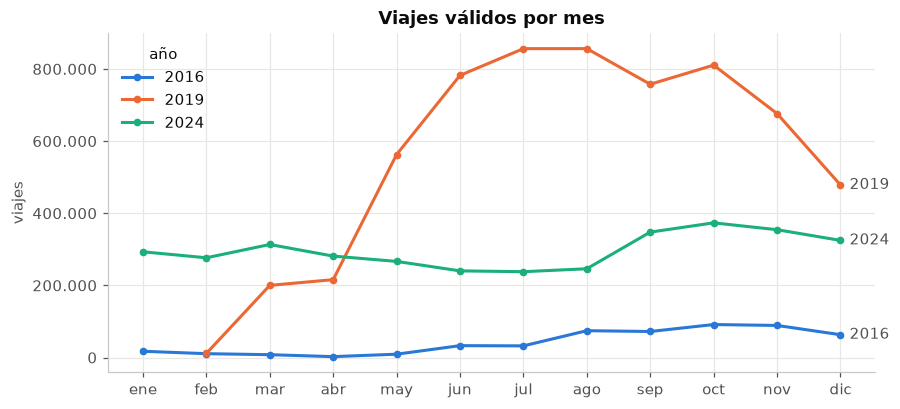

anio,2016,2019,2024
mes,,,
1,17421.0,NaN,293118.0
2,10677.0,11375.0,276530.0
3,7864.0,200037.0,313397.0
4,2509.0,215887.0,281188.0
5,9264.0,562725.0,266505.0
6,32949.0,782190.0,240231.0
7,32341.0,856306.0,237964.0
8,74405.0,856361.0,246102.0
9,72173.0,757629.0,347695.0


In [2]:
r1 = pd.read_csv(REP / "viajes_por_mes.csv")
fig, ax = plt.subplots(figsize=(9, 4))
for anio, d in r1.groupby("anio"):
    ax.plot(d.mes, d.cantidad_viajes, marker="o", markersize=4, color=COLOR_ANIO[anio], label=anio)
    ultimo = d.iloc[-1]; ax.annotate(str(anio), (ultimo.mes, ultimo.cantidad_viajes), xytext=(6, 0),
                                     textcoords="offset points", va="center", color=TINTA_2)
ax.set_xticks(range(1, 13), ["ene","feb","mar","abr","may","jun","jul","ago","sep","oct","nov","dic"])
ax.yaxis.set_major_formatter(miles); ax.set_ylabel("viajes"); ax.legend(title="año", loc="upper left")
ax.set_title("Viajes válidos por mes"); plt.show()
r1.pivot(index="mes", columns="anio", values="cantidad_viajes")

## 2. Top 10 estaciones de origen por año

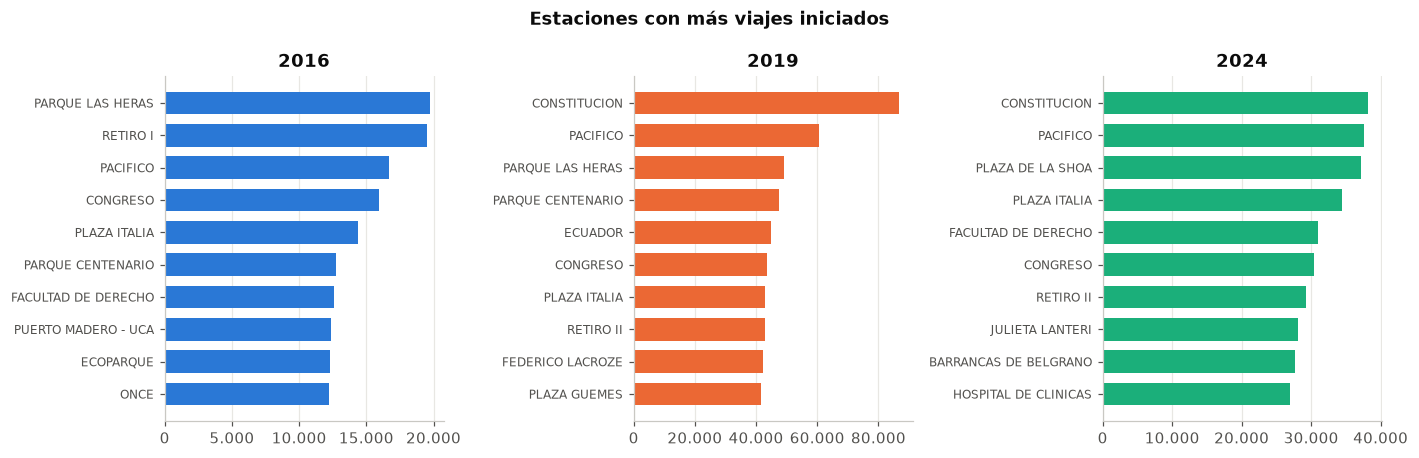

Estaciones que están en el top 10 de los tres años: ['CONGRESO', 'PACIFICO', 'PLAZA ITALIA']


In [3]:
r2 = pd.read_csv(REP / "top10_estaciones_por_anio.csv")
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
for ax, (anio, d) in zip(axes, r2.groupby("anio")):
    d = d.sort_values("ranking", ascending=False)
    ax.barh(d.nombre_estacion, d.cantidad_viajes, color=COLOR_ANIO[anio], height=0.7)
    ax.set_title(str(anio)); ax.xaxis.set_major_formatter(miles); ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", labelsize=8)
fig.suptitle("Estaciones con más viajes iniciados", fontweight="bold"); fig.tight_layout(); plt.show()
presencia = r2.groupby("nombre_estacion").anio.apply(lambda s: ", ".join(map(str, sorted(s))))
print("Estaciones que están en el top 10 de los tres años:", list(presencia[presencia.str.count(",") == 2].index))

## 3. Duración promedio por rango etario y género

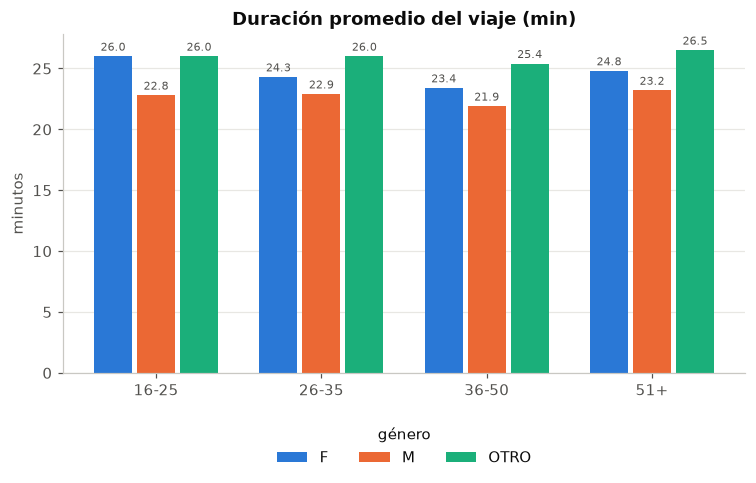

genero,DESCONOCIDO,F,M,OTRO
rango_etario,,,,
16-25,341,290148,555955,68011
26-35,578,392929,690770,143579
36-50,998,381250,567745,105148
51+,382,160996,211872,44189
DESCONOCIDO,27104,198,203,37


In [4]:
r3 = pd.read_csv(REP / "duracion_por_rango_y_genero.csv")
d = r3[(r3.genero != "DESCONOCIDO") & (r3.rango_etario != "DESCONOCIDO")]
tabla = d.pivot(index="rango_etario", columns="genero", values="duracion_promedio_min")
colores = {"F": "#2a78d6", "M": "#eb6834", "OTRO": "#1baf7a"}
fig, ax = plt.subplots(figsize=(8, 4)); ancho = 0.26
for i, g in enumerate(tabla.columns):
    x = [j + (i - 1) * ancho for j in range(len(tabla))]
    barras = ax.bar(x, tabla[g], width=ancho - 0.03, color=colores[g], label=g)
    ax.bar_label(barras, fmt="%.1f", fontsize=7, color=TINTA_2, padding=2)
ax.set_xticks(range(len(tabla)), tabla.index); ax.set_ylabel("minutos"); ax.grid(axis="x", visible=False)
ax.legend(title="género", ncols=3, loc="upper center", bbox_to_anchor=(0.5, -0.12))
ax.set_title("Duración promedio del viaje (min)"); plt.show()
r3.pivot(index="rango_etario", columns="genero", values="cantidad_viajes")

## 4. Viajes circulares

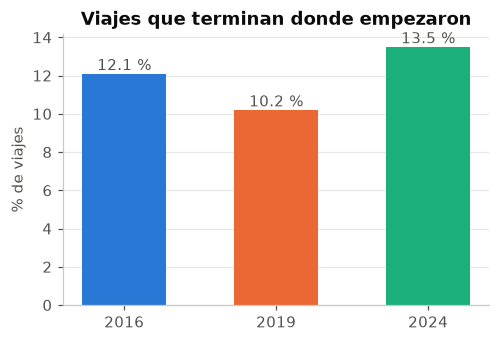

,anio,total_viajes,viajes_circulares,porcentaje_circulares
0,2016,503252,61021,12.1
1,2019,6207851,632955,10.2
2,2024,3555217,479184,13.5


In [5]:
r4 = pd.read_csv(REP / "viajes_circulares.csv")
fig, ax = plt.subplots(figsize=(5, 3.2))
b = ax.bar(r4.anio.astype(str), r4.porcentaje_circulares, color=[COLOR_ANIO[a] for a in r4.anio], width=0.55)
ax.bar_label(b, fmt="%.1f %%", color=TINTA_2); ax.set_ylabel("% de viajes"); ax.grid(axis="x", visible=False)
ax.set_title("Viajes que terminan donde empezaron"); plt.show()
r4

## 5. Calidad de datos

Qué porcentaje de cada año quedó en cuarentena y por qué. En 2016 casi todo es `FECHA_INVALIDA`: el 15,7 % de los
viajes no trae fecha de devolución.

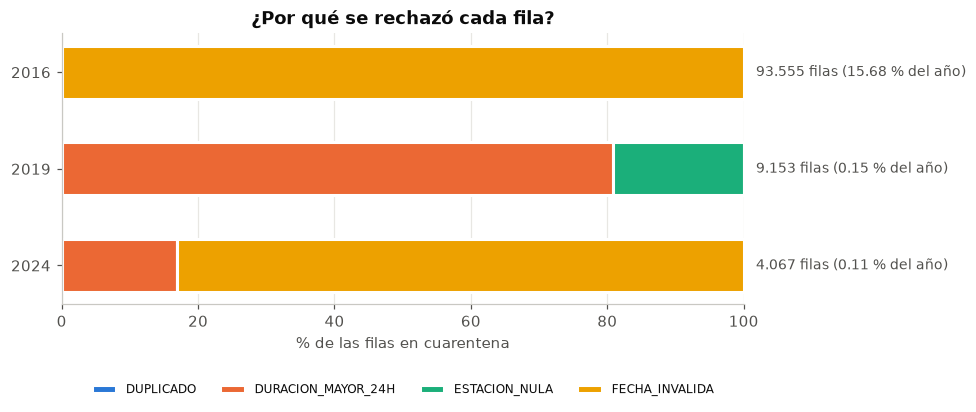

,filas_bronze,filas_silver,filas_cuarentena,porcentaje_cuarentena,cuarentena_duplicado,cuarentena_duracion_mayor_24h,cuarentena_estacion_nula,cuarentena_fecha_invalida
anio,,,,,,,,
2016,596807,503252,93555,15.68,0,0,0,93555
2019,6217004,6207851,9153,0.15,0,7393,1760,0
2024,3559284,3555217,4067,0.11,1,687,0,3379


In [6]:
r5 = pd.read_csv(REP / "calidad_por_anio.csv").set_index("anio")
motivos = [c for c in r5.columns if c.startswith("cuarentena_")]
comp = r5[motivos].div(r5.filas_cuarentena, axis=0) * 100   # composición: de lo rechazado, por qué
colores = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
fig, ax = plt.subplots(figsize=(8, 3.2)); izq = 0
for c, col in zip(motivos, colores):
    ax.barh(r5.index.astype(str), comp[c], left=izq, color=col, label=c.removeprefix("cuarentena_").upper(),
            height=0.55, edgecolor="white", linewidth=2); izq = izq + comp[c]
for i, (anio, fila) in enumerate(r5.iterrows()):
    ax.annotate(f"{fila.filas_cuarentena:,.0f} filas ({fila.porcentaje_cuarentena:.2f} % del año)".replace(",", "."),
                (100, i), xytext=(8, 0), textcoords="offset points", va="center", color=TINTA_2, fontsize=9)
ax.set_xlim(0, 100); ax.set_xlabel("% de las filas en cuarentena"); ax.grid(axis="y", visible=False); ax.invert_yaxis()
ax.legend(fontsize=8, ncols=4, loc="upper center", bbox_to_anchor=(0.5, -0.25))
ax.set_title("¿Por qué se rechazó cada fila?"); plt.show()
r5

## 6. Consultas SQL con DuckDB

DuckDB lee los Parquet de gold directamente, sin cargarlos a ninguna base (sección 3.6 del enunciado).
Primero, el reporte 4 recalculado en SQL tiene que dar lo mismo que el de pandas:

In [7]:
sql = duckdb.sql("""
    SELECT f.anio, COUNT(*) AS total_viajes, SUM(v.es_circular::INT) AS viajes_circulares,
           ROUND(100.0 * SUM(v.es_circular::INT) / COUNT(*), 1) AS porcentaje_circulares
    FROM 'data/gold/fact_viajes/data.parquet' v
    JOIN 'data/gold/dim_fecha/data.parquet'  f USING (fecha_key)
    GROUP BY f.anio ORDER BY f.anio
""").df()
pd.testing.assert_frame_equal(sql, r4, check_dtype=False)
print("SQL y pandas coinciden"); sql

SQL y pandas coinciden


,anio,total_viajes,viajes_circulares,porcentaje_circulares
0,2016,503252,61021.0,12.1
1,2019,6207851,632955.0,10.2
2,2024,3555217,479184.0,13.5


¿A qué hora se usa la bici? Laborables vs fin de semana (porcentaje de los viajes de cada tipo de día):

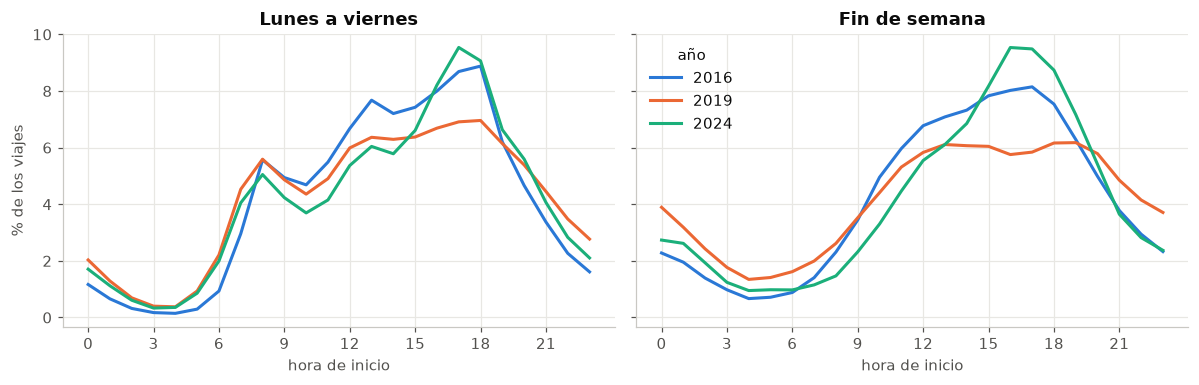

In [8]:
horas = duckdb.sql("""
    SELECT f.anio, f.es_fin_de_semana, v.hora_inicio, COUNT(*) AS viajes
    FROM 'data/gold/fact_viajes/data.parquet' v
    JOIN 'data/gold/dim_fecha/data.parquet'  f USING (fecha_key)
    GROUP BY ALL
""").df()
horas["pct"] = 100 * horas.viajes / horas.groupby(["anio", "es_fin_de_semana"]).viajes.transform("sum")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, (finde, d) in zip(axes, horas.groupby("es_fin_de_semana")):
    for anio, e in d.sort_values("hora_inicio").groupby("anio"):
        ax.plot(e.hora_inicio, e.pct, color=COLOR_ANIO[anio], label=anio)
    ax.set_title("Fin de semana" if finde else "Lunes a viernes"); ax.set_xticks(range(0, 24, 3)); ax.set_xlabel("hora de inicio")
axes[0].set_ylabel("% de los viajes"); axes[1].legend(title="año"); fig.tight_layout(); plt.show()

Los recorridos (origen → destino, sin contar circulares) más repetidos de 2024:

In [9]:
duckdb.sql("""
    SELECT o.nombre_estacion AS origen, d.nombre_estacion AS destino, COUNT(*) AS viajes,
           ROUND(MEDIAN(v.duracion_min), 1) AS mediana_min
    FROM 'data/gold/fact_viajes/data.parquet' v
    JOIN 'data/gold/dim_fecha/data.parquet'    f ON v.fecha_key = f.fecha_key
    JOIN 'data/gold/dim_estacion/data.parquet' o ON v.id_estacion_origen  = o.id_estacion
    JOIN 'data/gold/dim_estacion/data.parquet' d ON v.id_estacion_destino = d.id_estacion
    WHERE f.anio = 2024 AND NOT v.es_circular
    GROUP BY ALL ORDER BY viajes DESC LIMIT 10
""").df()

,origen,destino,viajes,mediana_min
0,PLAZA DE LA SHOA,PACIFICO,4058,5.8
1,PACIFICO,PLAZA DE LA SHOA,4055,5.6
2,MALBA,FACULTAD DE DERECHO,2920,9.0
3,FACULTAD DE DERECHO,MALBA,2850,7.4
4,BARRIO 31,RETIRO II,2220,7.6
5,RODRIGO BUENO,PLAZA ROMA,2124,12.0
6,RETIRO II,BARRIO 31,1968,8.4
7,MADERO OFFICE,RETIRO II,1943,7.8
8,SAN JOSE DE FLORES,GALICIA,1894,8.2
9,PLAZOLETA RIO DE LA PLATA,PLAZA ITALIA,1865,10.8


## 7. Conclusiones

**Uso del sistema**
- **2019 fue el año de mayor uso:** 6,2 millones de viajes válidos, con un pico de unos 856 mil por mes en julio y agosto. En 2024 hubo 3,6 millones, con una curva más pareja que sube en primavera (septiembre a noviembre). En 2016 hubo 0,5 millones: el sistema era otro, con 99 estaciones contra unas 400 en 2019 y 2024.
- 2019 arranca el 9 de febrero: el dataset publicado no trae enero, así que ese "crecimiento" de febrero a mayo es en parte un artefacto de los datos.
- **Patrón horario:** de lunes a viernes hay dos picos claros, a las 8 y a las 18 (ida y vuelta del trabajo o del estudio). El fin de semana el uso es de tarde, sin picos. En 2019 se ve más uso nocturno que en los otros años.

**Estaciones**
- PACIFICO, CONGRESO y PLAZA ITALIA están en el top 10 los tres años. CONSTITUCION, que no existía en 2016, lidera 2019 y 2024.
- En 2024 entran al top estaciones fuera del microcentro (PLAZA DE LA SHOA, JULIETA LANTERI, BARRANCAS DE BELGRANO), coherente con la expansión de la red.
- El top 2016 es correcto **gracias a la reconciliación de ids** (D3): sin ella, varios puestos mostraban el nombre de otra estación (por ejemplo, el id 59 era CORONEL DIAZ en 2016 e INDEPENDENCIA después).

**Usuarios**
- En todos los rangos etarios los viajes de los hombres son los más cortos (22 a 23 min en promedio), los de las mujeres duran entre 23 y 26 min y los de `OTRO` entre 25 y 26,5 min. Las diferencias son chicas, de 2 a 4 minutos.
- Entre el 10 % y el 13,5 % de los viajes son circulares; 2024 tiene la proporción más alta, lo que sugiere más uso recreativo (es una hipótesis: los datos no dicen el motivo del viaje).

**Calidad y limitaciones**
- 2019 y 2024 tienen menos de 0,2 % de rechazos. 2016 tiene 15,7 %, todos por viajes sin fecha de devolución.
- Los datos de 2016 parecen perturbados por la fuente: la duración informada no tiene relación con las fechas (D4).
- Solo el 37 % de los viajes con usuario se puede cruzar con dim_usuario, porque los archivos traen solo las altas de cada año (D14). Por eso el reporte 3 representa a ese subconjunto, no a todos los viajes.